In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
data = pd.read_csv("C:/Users/Hajapure/OneDrive/Desktop/data science/home_prices.csv.xls")
data.head()

,area_sqr_ft,bedrooms,color,price_lakhs
0,3774,2,Red,216
1,1460,3,Gray,88
2,1894,4,Gray,147
3,1730,2,Blue,84
4,1695,1,Blue,77


In [48]:
data = pd.get_dummies(data, dtype=int)
data.head()

,area_sqr_ft,bedrooms,price_lakhs,color_Blue,color_Gray,color_Green,color_Red,color_White,color_Yellow
0,3774,2,216,0,0,0,1,0,0
1,1460,3,88,0,1,0,0,0,0
2,1894,4,147,0,1,0,0,0,0
3,1730,2,84,1,0,0,0,0,0
4,1695,1,77,1,0,0,0,0,0


<Axes: >

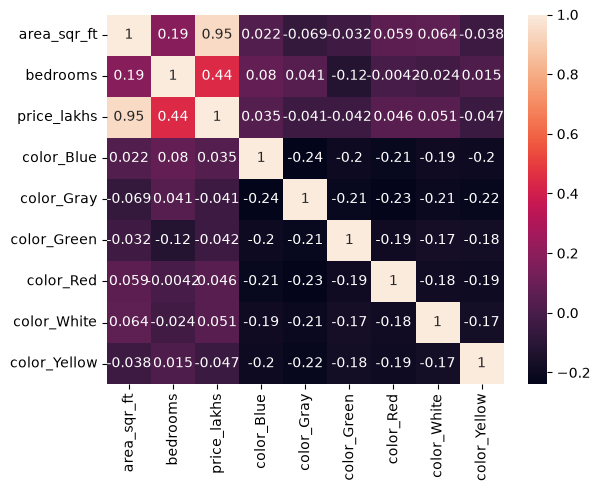

In [49]:
sns.heatmap(data.corr(), annot=True)

In [50]:
#colors not able to predict price(corr comes between -0.3 to +0.3),so remove colors

Calculate VIF

In [51]:
data = pd.read_csv("C:/Users/Hajapure/OneDrive/Desktop/data science/salaries for VIF.csv.xls")
data.head()

,Years of Experience,Education Level,Age,Location Factor,Salary
0,29,1,49,7,124204
1,27,3,45,4,125948
2,20,4,41,8,116078
3,14,4,37,5,106486
4,20,3,42,7,113297


<Axes: >

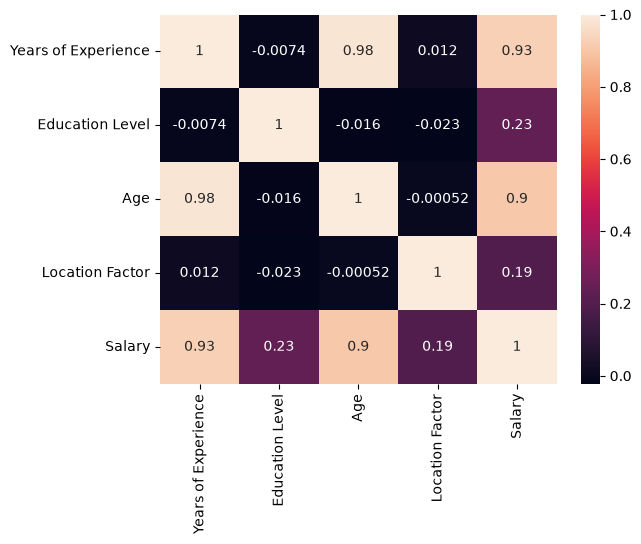

In [52]:
sns.heatmap(data.corr(),annot=True)

In [53]:
X= data.iloc[:,0:1]
y= data.iloc[:,-1]

In [54]:
from sklearn.model_selection import train_test_split

In [55]:
X_train, X_test, y_train, y_test=train_test_split(X, y, random_state=3,test_size=0.2)

In [56]:
from sklearn.linear_model import LinearRegression

In [57]:
model = LinearRegression()

In [58]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2001.63]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Years of Experience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.039e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [59]:
train_pred = model.predict(X_train)

In [60]:
from sklearn.metrics import r2_score

In [61]:
r2_score(y_train, train_pred)

0.8656347307652802

In [62]:
data.head()

,Years of Experience,Education Level,Age,Location Factor,Salary
0,29,1,49,7,124204
1,27,3,45,4,125948
2,20,4,41,8,116078
3,14,4,37,5,106486
4,20,3,42,7,113297


In [63]:
data1 = data.drop(['Salary'], axis=1)

In [64]:
data1.head()

,Years of Experience,Education Level,Age,Location Factor
0,29,1,49,7
1,27,3,45,4
2,20,4,41,8
3,14,4,37,5
4,20,3,42,7


In [65]:
data1.columns

Index(['Years of Experience', 'Education Level', 'Age', 'Location Factor'], dtype='str')

pip install Statsmodels

In [66]:
data1.shape[1]

4

In [70]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
variance_inflation_factor(data1, 0)

np.float64(27.789896607809407)

In [71]:
def calculateVIF(df):
    columns = df.columns
    res = pd.DataFrame({'Columns Name': columns})
    val =[]
    for i in range(df .shape[1]):
        vif = variance_inflation_factor(df,1)
        val.append(vif)
    res['VIFs'] = val
    return res

In [72]:
calculateVIF(data1)

,Columns Name,VIFs
0,Years of Experience,1.002909
1,Education Level,1.002909
2,Age,1.002909
3,Location Factor,1.002909
